<a href="https://colab.research.google.com/github/Ravi-ranjan1801/Data-Warehousing-Mining-Lab/blob/main/DWM_Lab_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Lab - 10 (Association Rule Mining using Apriori)**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import zipfile
import io
import os

from itertools import combinations
from google.colab import files

In [2]:
uploaded = files.upload()

zip_name = next(iter(uploaded))

DATA_DIR = "/content/dwm_data"

os.makedirs(DATA_DIR, exist_ok=True)

with zipfile.ZipFile(io.BytesIO(uploaded[zip_name])) as z:
    z.extractall(DATA_DIR)

print("Dataset extracted successfully!")

Saving DWM_Practical_Datasets.zip to DWM_Practical_Datasets.zip
Dataset extracted successfully!


In [3]:
file_path = os.path.join(
    DATA_DIR,
    "05_apriori_market_basket.csv"
)

df = pd.read_csv(file_path)

print("Dataset Shape:", df.shape)

display(df.head(10))

print("\nDataset Information:")

df.info()

Dataset Shape: (80, 2)


,Transaction_ID,Items
0,T001,Biscuits;Bread;Butter;Coffee;Milk
1,T002,Apples;Milk
2,T003,Cheese;Coffee
3,T004,Biscuits;Butter;Coffee;Tea
4,T005,Bread;Butter
5,T006,Biscuits;Bread;Butter
6,T007,Biscuits;Butter;Eggs;Tea
7,T008,Biscuits;Bread;Butter;Tea
8,T009,Bread;Butter;Milk
9,T010,Eggs;Milk



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80 entries, 0 to 79
Data columns (total 2 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Transaction_ID  80 non-null     object
 1   Items           80 non-null     object
dtypes: object(2)
memory usage: 1.4+ KB


In [4]:
transactions = []

for items in df['Items']:

    item_set = set(
        item.strip()
        for item in str(items).split(';')
        if item.strip()
    )

    transactions.append(item_set)

print("Total Transactions:", len(transactions))

print("\nFirst Five Transactions:")

for i in range(5):
    print(transactions[i])

Total Transactions: 80

First Five Transactions:
{'Milk', 'Coffee', 'Butter', 'Bread', 'Biscuits'}
{'Milk', 'Apples'}
{'Cheese', 'Coffee'}
{'Biscuits', 'Butter', 'Tea', 'Coffee'}
{'Butter', 'Bread'}


In [5]:
all_items = sorted(
    set().union(*transactions)
)

print("Unique Items:")

print(all_items)

print("\nTotal Unique Items:", len(all_items))

Unique Items:
['Apples', 'Bananas', 'Biscuits', 'Bread', 'Butter', 'Cheese', 'Coffee', 'Eggs', 'Milk', 'Tea']

Total Unique Items: 10


In [6]:
binary_matrix = pd.DataFrame(
    [
        [int(item in transaction) for item in all_items]
        for transaction in transactions
    ],
    index=df['Transaction_ID'],
    columns=all_items
)

binary_matrix.index.name = 'Transaction_ID'

print("Binary Transaction Matrix:")

display(binary_matrix.head(10))

Binary Transaction Matrix:


,Apples,Bananas,Biscuits,Bread,Butter,Cheese,Coffee,Eggs,Milk,Tea
Transaction_ID,,,,,,,,,,
T001,0,0,1,1,1,0,1,0,1,0
T002,1,0,0,0,0,0,0,0,1,0
T003,0,0,0,0,0,1,1,0,0,0
T004,0,0,1,0,1,0,1,0,0,1
T005,0,0,0,1,1,0,0,0,0,0
T006,0,0,1,1,1,0,0,0,0,0
T007,0,0,1,0,1,0,0,1,0,1
T008,0,0,1,1,1,0,0,0,0,1
T009,0,0,0,1,1,0,0,0,1,0


In [7]:
def apriori(transactions, min_support):

    n = len(transactions)

    items = sorted(
        set().union(*transactions)
    )

    support_cache = {}

    # Function to calculate support
    def get_support(itemset):

        itemset = frozenset(itemset)

        if itemset not in support_cache:

            count = sum(
                itemset.issubset(t)
                for t in transactions
            )

            support_cache[itemset] = count / n

        return support_cache[itemset]

    # Generate frequent 1-itemsets
    current = []

    for item in items:

        candidate = frozenset([item])

        if get_support(candidate) >= min_support:

            current.append(candidate)

    frequent_supports = {}

    # Generate larger frequent itemsets
    while current:

        for itemset in current:

            frequent_supports[itemset] = (
                get_support(itemset)
            )

        k = len(current[0]) + 1

        previous_set = set(current)

        candidates = set()

        # Candidate generation and pruning
        for a, b in combinations(current, 2):

            candidate = a | b

            if len(candidate) == k:

                all_subsets_frequent = all(
                    frozenset(subset) in previous_set
                    for subset in combinations(
                        sorted(candidate), k - 1
                    )
                )

                if all_subsets_frequent:

                    candidates.add(candidate)

        current = [
            candidate
            for candidate in candidates
            if get_support(candidate) >= min_support
        ]

    return frequent_supports

In [8]:
min_support = 0.15

frequent_itemsets = apriori(
    transactions,
    min_support
)

print("Minimum Support:", min_support)

print(
    "Total Frequent Itemsets:",
    len(frequent_itemsets)
)

Minimum Support: 0.15
Total Frequent Itemsets: 32


In [9]:
def create_itemset_table(frequent_supports, n):

    rows = []

    for itemset, support in frequent_supports.items():

        rows.append({
            'Itemset': ', '.join(sorted(itemset)),
            'Length': len(itemset),
            'Support': support,
            'Support Count': round(support * n)
        })

    result = pd.DataFrame(rows)

    return result.sort_values(
        ['Length', 'Support'],
        ascending=[True, False]
    ).reset_index(drop=True)


frequent_df = create_itemset_table(
    frequent_itemsets,
    len(transactions)
)

display(frequent_df.round(4))

,Itemset,Length,Support,Support Count
0,Bread,1,0.7250,58
1,Milk,1,0.6125,49
2,Biscuits,1,0.5750,46
3,Butter,1,0.4125,33
4,Tea,1,0.3750,30
5,Coffee,1,0.3500,28
6,Cheese,1,0.1875,15
7,Eggs,1,0.1625,13
8,"Bread, Milk",2,0.5250,42
9,"Biscuits, Bread",2,0.3875,31


In [10]:
def generate_association_rules(
    frequent_supports,
    min_confidence
):

    rules = []

    for itemset, itemset_support in frequent_supports.items():

        if len(itemset) < 2:
            continue

        # Generate all possible antecedents
        for size in range(1, len(itemset)):

            for antecedent_tuple in combinations(
                sorted(itemset), size
            ):

                antecedent = frozenset(
                    antecedent_tuple
                )

                consequent = itemset - antecedent

                support_antecedent = (
                    frequent_supports[antecedent]
                )

                support_consequent = (
                    frequent_supports[consequent]
                )

                # Calculate confidence
                confidence = (
                    itemset_support /
                    support_antecedent
                )

                # Calculate lift
                lift = (
                    confidence /
                    support_consequent
                )

                if confidence >= min_confidence:

                    rules.append({

                        'Antecedent': ', '.join(
                            sorted(antecedent)
                        ),

                        'Consequent': ', '.join(
                            sorted(consequent)
                        ),

                        'Support': itemset_support,

                        'Confidence': confidence,

                        'Lift': lift
                    })

    rules_df = pd.DataFrame(rules)

    if not rules_df.empty:

        rules_df = rules_df.sort_values(
            ['Lift', 'Confidence'],
            ascending=False
        ).reset_index(drop=True)

    return rules_df

In [11]:
min_confidence = 0.50

rules_df = generate_association_rules(
    frequent_itemsets,
    min_confidence
)

print("Minimum Confidence:", min_confidence)

print("Total Association Rules:", len(rules_df))

display(rules_df.head(15).round(4))

Minimum Confidence: 0.5
Total Association Rules: 42


,Antecedent,Consequent,Support,Confidence,Lift
0,"Bread, Tea",Biscuits,0.2125,0.9444,1.6425
1,"Milk, Tea",Biscuits,0.1750,0.9333,1.6232
2,"Butter, Tea",Biscuits,0.1500,0.9231,1.6054
3,Tea,Biscuits,0.3375,0.9000,1.5652
4,Biscuits,Tea,0.3375,0.5870,1.5652
5,"Biscuits, Milk",Tea,0.1750,0.5833,1.5556
6,Tea,"Biscuits, Bread",0.2125,0.5667,1.4624
7,"Biscuits, Bread",Tea,0.2125,0.5484,1.4624
8,"Biscuits, Butter",Tea,0.1500,0.5455,1.4545
9,"Biscuits, Milk",Coffee,0.1500,0.5000,1.4286


In [12]:
support_thresholds = [0.15, 0.20]

comparison_results = {}

for threshold in support_thresholds:

    print("\n" + "=" * 50)

    print("MINIMUM SUPPORT:", threshold)

    # Generate frequent itemsets
    freq = apriori(
        transactions,
        threshold
    )

    # Generate association rules
    rules = generate_association_rules(
        freq,
        min_confidence=0.50
    )

    # Display frequent itemsets
    freq_table = create_itemset_table(
        freq,
        len(transactions)
    )

    print("\nFrequent Itemsets:")

    display(freq_table.round(4))

    # Display top rules
    print("\nTop 10 Association Rules:")

    display(rules.head(10).round(4))

    comparison_results[threshold] = {
        'frequent': freq,
        'rules': rules,
        'freq_count': len(freq),
        'rule_count': len(rules)
    }


MINIMUM SUPPORT: 0.15

Frequent Itemsets:


,Itemset,Length,Support,Support Count
0,Bread,1,0.7250,58
1,Milk,1,0.6125,49
2,Biscuits,1,0.5750,46
3,Butter,1,0.4125,33
4,Tea,1,0.3750,30
5,Coffee,1,0.3500,28
6,Cheese,1,0.1875,15
7,Eggs,1,0.1625,13
8,"Bread, Milk",2,0.5250,42
9,"Biscuits, Bread",2,0.3875,31



Top 10 Association Rules:


,Antecedent,Consequent,Support,Confidence,Lift
0,"Bread, Tea",Biscuits,0.2125,0.9444,1.6425
1,"Milk, Tea",Biscuits,0.1750,0.9333,1.6232
2,"Butter, Tea",Biscuits,0.1500,0.9231,1.6054
3,Tea,Biscuits,0.3375,0.9000,1.5652
4,Biscuits,Tea,0.3375,0.5870,1.5652
5,"Biscuits, Milk",Tea,0.1750,0.5833,1.5556
6,Tea,"Biscuits, Bread",0.2125,0.5667,1.4624
7,"Biscuits, Bread",Tea,0.2125,0.5484,1.4624
8,"Biscuits, Butter",Tea,0.1500,0.5455,1.4545
9,"Biscuits, Milk",Coffee,0.1500,0.5000,1.4286



MINIMUM SUPPORT: 0.2

Frequent Itemsets:


,Itemset,Length,Support,Support Count
0,Bread,1,0.7250,58
1,Milk,1,0.6125,49
2,Biscuits,1,0.5750,46
3,Butter,1,0.4125,33
4,Tea,1,0.3750,30
5,Coffee,1,0.3500,28
6,"Bread, Milk",2,0.5250,42
7,"Biscuits, Bread",2,0.3875,31
8,"Bread, Butter",2,0.3500,28
9,"Biscuits, Tea",2,0.3375,27



Top 10 Association Rules:


,Antecedent,Consequent,Support,Confidence,Lift
0,"Bread, Tea",Biscuits,0.2125,0.9444,1.6425
1,Tea,Biscuits,0.3375,0.9000,1.5652
2,Biscuits,Tea,0.3375,0.5870,1.5652
3,Tea,"Biscuits, Bread",0.2125,0.5667,1.4624
4,"Biscuits, Bread",Tea,0.2125,0.5484,1.4624
5,"Biscuits, Bread",Butter,0.2125,0.5484,1.3294
6,Butter,"Biscuits, Bread",0.2125,0.5152,1.3294
7,Coffee,Biscuits,0.2625,0.7500,1.3043
8,"Butter, Milk",Bread,0.2000,0.9412,1.2982
9,Milk,Bread,0.5250,0.8571,1.1823


In [13]:
top_rule = comparison_results[0.15]['rules'].iloc[0]

print("Strongest Association Rule:")

print(
    top_rule['Antecedent'],
    "---->",
    top_rule['Consequent']
)

print("Support:", round(top_rule['Support'], 4))

print("Confidence:", round(top_rule['Confidence'], 4))

print("Lift:", round(top_rule['Lift'], 4))

Strongest Association Rule:
Bread, Tea ----> Biscuits
Support: 0.2125
Confidence: 0.9444
Lift: 1.6425


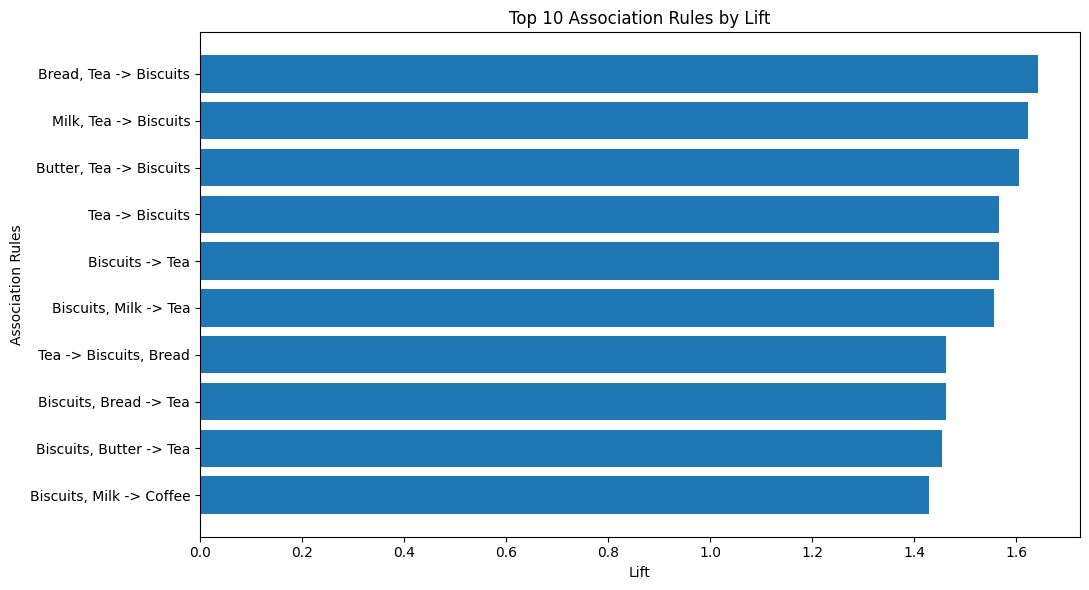

In [14]:
top_10 = comparison_results[0.15]['rules'].head(10).copy()

labels = (
    top_10['Antecedent']
    + ' -> '
    + top_10['Consequent']
)

plt.figure(figsize=(11, 6))

plt.barh(
    labels[::-1],
    top_10['Lift'].values[::-1]
)

plt.xlabel('Lift')

plt.ylabel('Association Rules')

plt.title('Top 10 Association Rules by Lift')

plt.tight_layout()

plt.show()

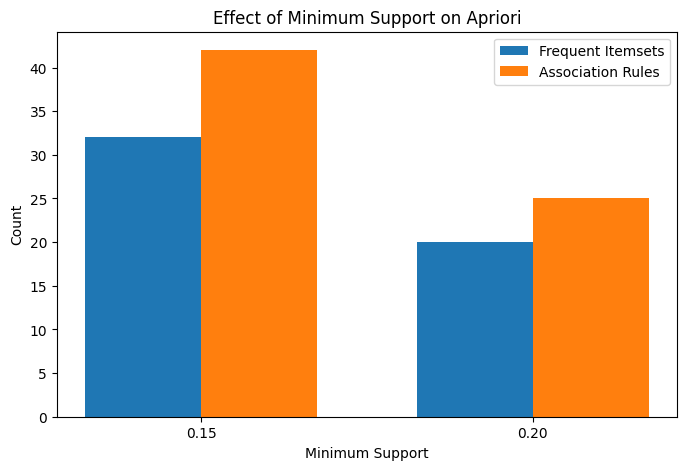

In [15]:
threshold_labels = ['0.15', '0.20']

itemset_counts = [
    comparison_results[0.15]['freq_count'],
    comparison_results[0.20]['freq_count']
]

rule_counts = [
    comparison_results[0.15]['rule_count'],
    comparison_results[0.20]['rule_count']
]

x = np.arange(len(threshold_labels))

width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    x - width/2,
    itemset_counts,
    width,
    label='Frequent Itemsets'
)

plt.bar(
    x + width/2,
    rule_counts,
    width,
    label='Association Rules'
)

plt.xticks(x, threshold_labels)

plt.xlabel('Minimum Support')

plt.ylabel('Count')

plt.title('Effect of Minimum Support on Apriori')

plt.legend()

plt.show()

## **Conclusion**
The Apriori algorithm was successfully implemented on the market basket dataset containing 80 transactions. The algorithm identified frequent itemsets and generated association rules using minimum support and confidence thresholds. Support, Confidence and Lift were calculated for each rule. The strongest association found was Bread + Tea → Biscuits, with support 0.2125, confidence 0.9444 and lift 1.6425. Comparison of minimum support thresholds 0.15 and 0.20 showed that increasing minimum support reduces the number of frequent itemsets and association rules.